In [1]:
import pandas as pd
import numpy as np
from librosa.util import find_files
import librosa
import os
import pickle
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
import torch.nn.functional as F
from dataset import ASVspoof2019
from evaluate_tDCF_asvspoof19 import compute_eer_and_tdcf
from collections import defaultdict
from utils import visualize

In [2]:
import pandas as pd
import numpy as np
from librosa.util import find_files
import librosa
import os
import pickle
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
import torch.nn.functional as F
from dataset import ASVspoof2019
from evaluate_tDCF_asvspoof19 import compute_eer_and_tdcf
from collections import defaultdict
from utils import visualize, get_features, compare_exps, visualize_dev_and_eval, test_checkpoint_model

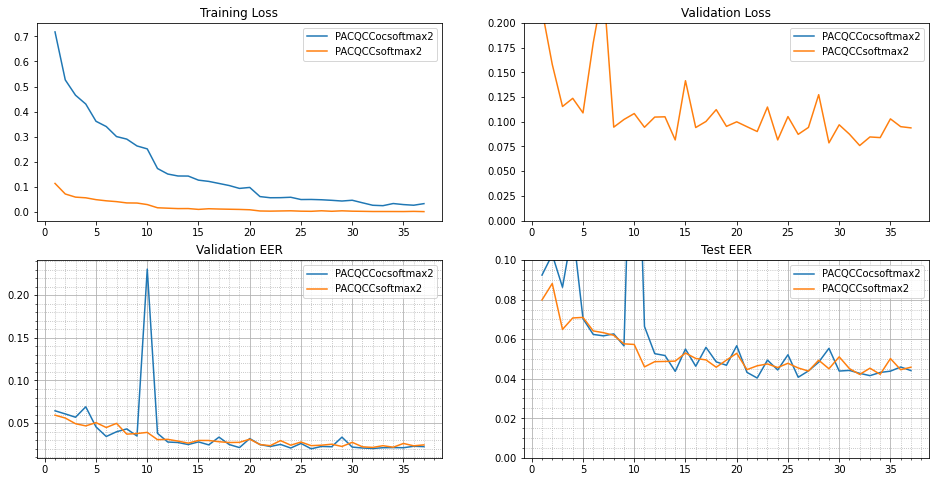

In [4]:
exp_dirs = ["PACQCCocsoftmax2", "PACQCCsoftmax2"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1118")

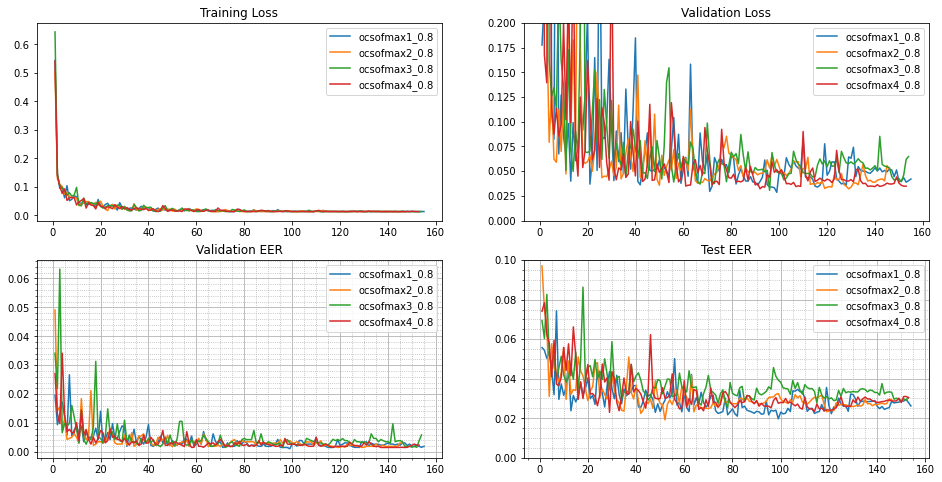

In [4]:
exp_dirs = ["ocsofmax1_0.8", "ocsofmax2_0.8", "ocsofmax3_0.8", "ocsofmax4_0.8"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1201")

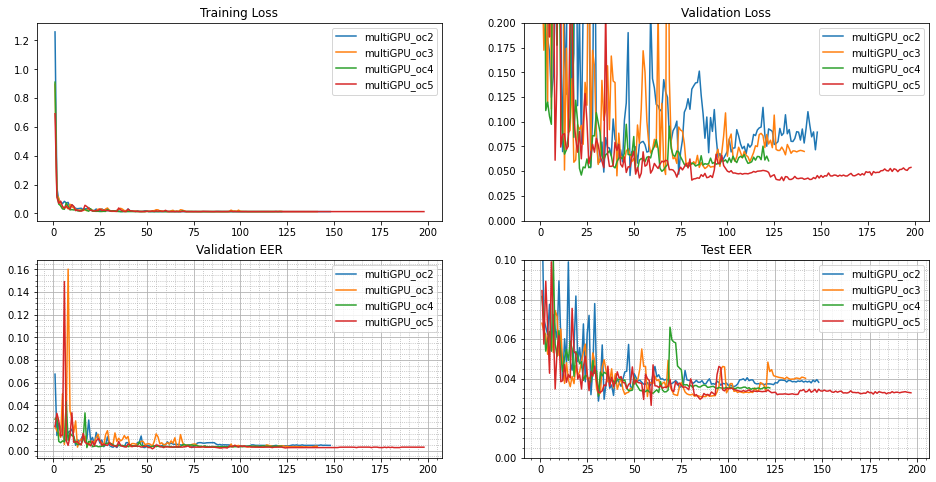

In [2]:
exp_dirs = ["multiGPU_oc2", "multiGPU_oc3", "multiGPU_oc4", "multiGPU_oc5"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1206")

In [3]:
def compare_exps(exp_dirs, root_dir='/home/neil/AIR-ASVspoof/experiments'):
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 8))
    for folder in exp_dirs:
        out_fold = os.path.join(root_dir, folder)
        train_log_file = os.path.join(out_fold, "train_loss.log")
        dev_log_file = os.path.join(out_fold, "dev_loss.log")
        with open(train_log_file, "r") as train_log:
            x = np.array([[float(i) for i in line[0:-1].split('\t')] for line in train_log.readlines()[1:]])
            it_per_batch = int(x[:, 1].max()) + 1
            length = x.shape[0]
            y = x[:length// it_per_batch * it_per_batch, 2].reshape(-1, it_per_batch)
            y = y.mean(axis=1)
#             x = x[it_per_batch - 1::it_per_batch]
            ax1.plot(range(1, len(y) + 1), y)
            #     ax1.set_xticks(np.where(x[:,1]==0)[0][::10])
            #     ax1.set_xticklabels(np.arange(np.sum(x[:,1]==0))*10)
            ax1.set_title("Training Loss")
#             ax1.set_ylim([0, 0.05])
            ax1.grid()
            ax1.legend(exp_dirs)
        with open(dev_log_file, "r") as dev_log:
            x = np.array([[float(i) for i in line[0:-1].split('\t')] for line in dev_log.readlines()[1:]])
            ax2.plot(range(1, len(x) + 1), x[:, 1])
            ax2.set_title("Validation Loss")
#             ax2.set_ylim([0, 0.2])
            ax2.legend(exp_dirs)

            ax3.plot(range(1, len(x) + 1), x[:, 2])
            ax3.set_title("Validation EER")
            ax3.minorticks_on()
            ax3.grid(b=True, which='major', linestyle='-')
            ax3.grid(b=True, which='minor', linestyle=':')
            ax3.legend(exp_dirs)
        with open(os.path.join(out_fold, "test_loss.log"), "r") as dev_eer:
            x = np.array([[float(i) for i in line[0:-1].split('\t')] for line in dev_eer.readlines()[1:]])
            ax4.plot(range(1, len(x) + 1), x[:, 2])
            ax4.set_title("Test EER")
            ax4.minorticks_on()
            ax4.grid(b=True, which='major', linestyle='-')
            ax4.grid(b=True, which='minor', linestyle=':')
            ax4.set_ylim([0, 0.1])
            ax4.legend(exp_dirs)
    plt.show()

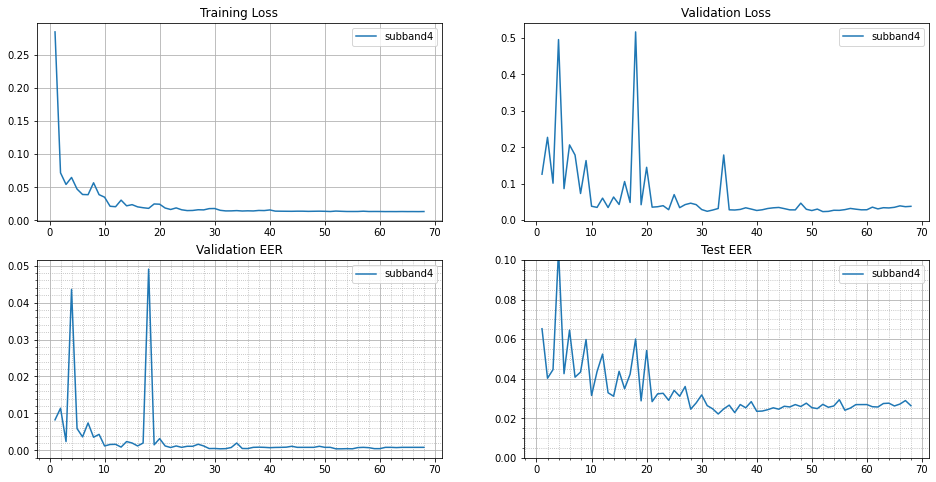

In [5]:
exp_dirs = ["subband4"]
compare_exps(exp_dirs, "/data/neil/analyse/subband0225")

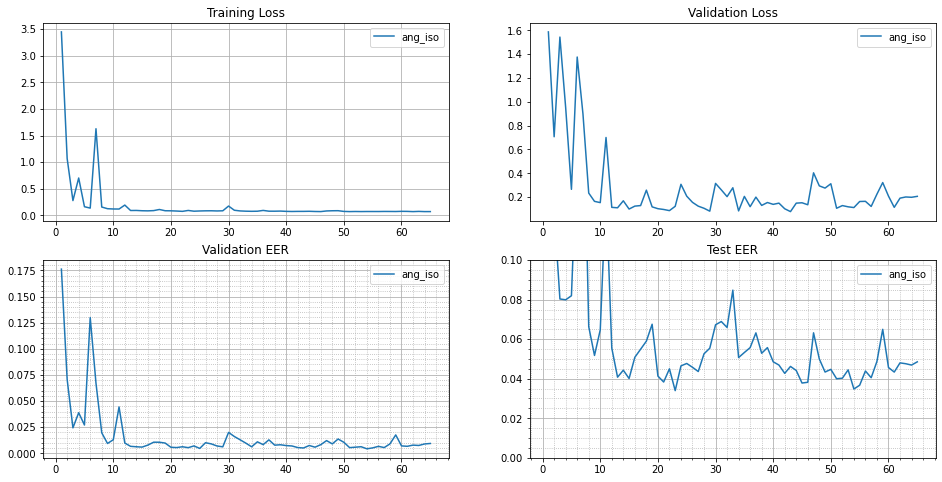

In [21]:
exp_dirs = ["ang_iso"]
compare_exps(exp_dirs, "/data/neil/analyse/models1221")

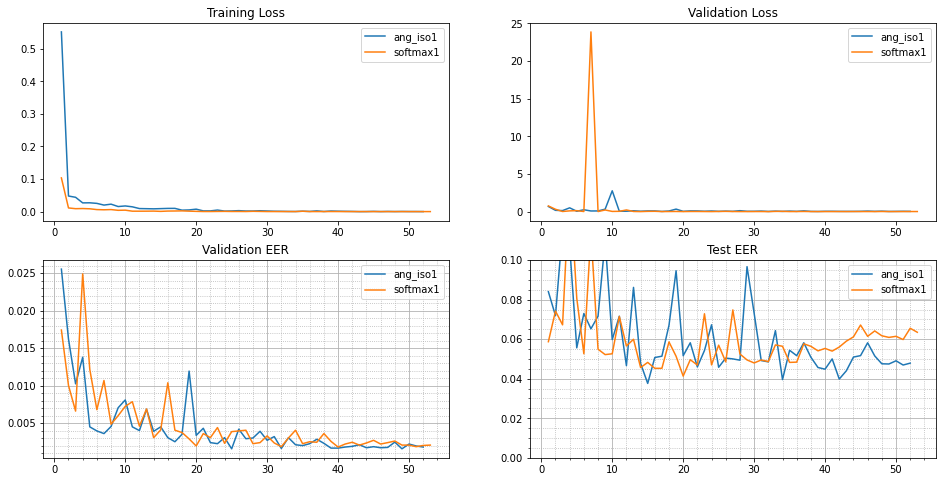

In [26]:
exp_dirs = ["ang_iso1", "softmax1"]
compare_exps(exp_dirs, "/data/neil/analyse/models1221")

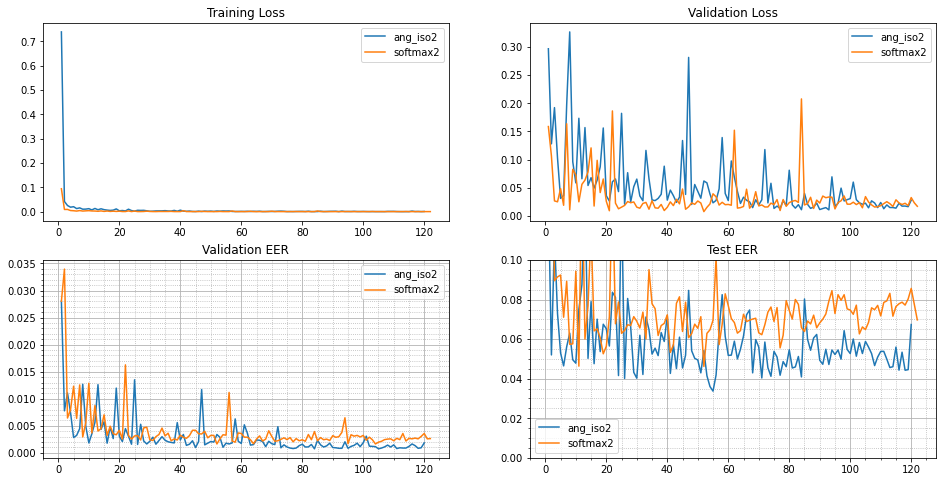

In [25]:
exp_dirs = ["ang_iso2", "softmax2"]
compare_exps(exp_dirs, "/data/neil/analyse/models1221")

In [ ]:
# compare neighbor models
# mismatch EER and loss
# training loss each iteration
# change moving average when plot

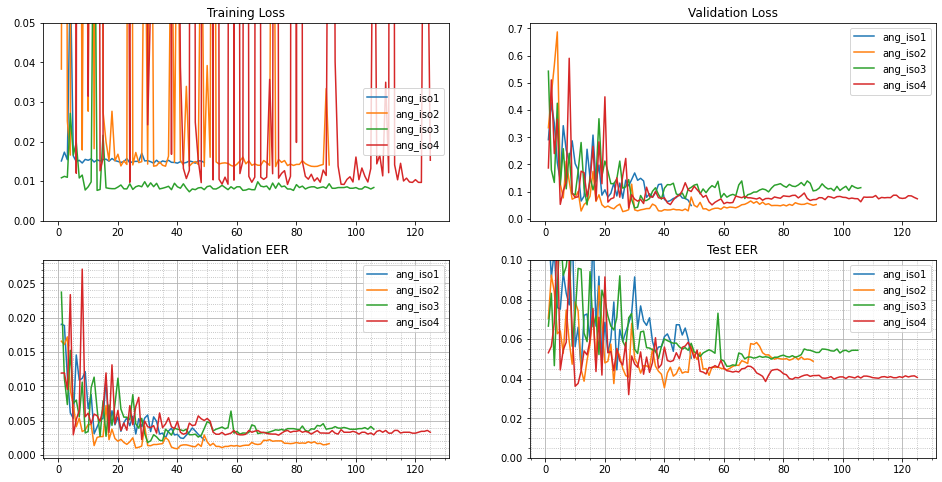

In [50]:
exp_dirs = ["ang_iso1", "ang_iso2", "ang_iso3", "ang_iso4"]
compare_exps(exp_dirs, "/data/neil/analyse/models1223")

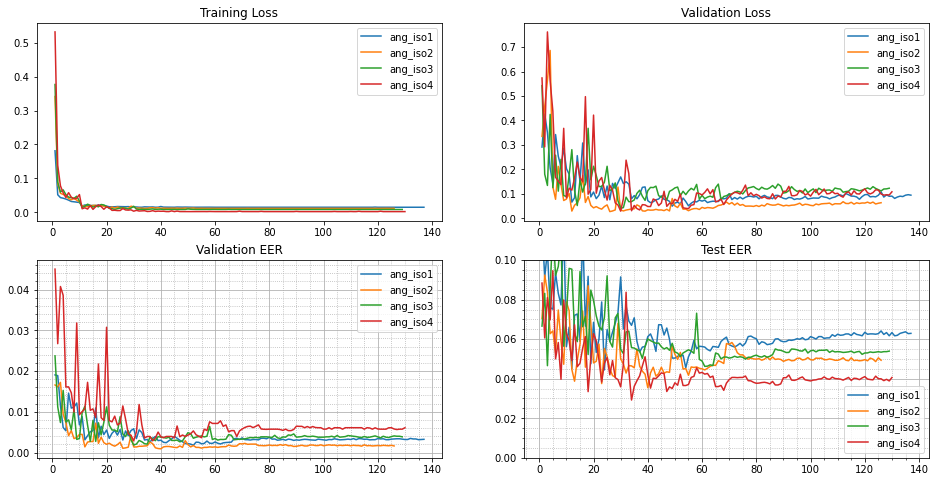

In [24]:
exp_dirs = ["ang_iso1", "ang_iso2", "ang_iso3", "ang_iso4"]
compare_exps(exp_dirs, "/data/neil/analyse/models1223")

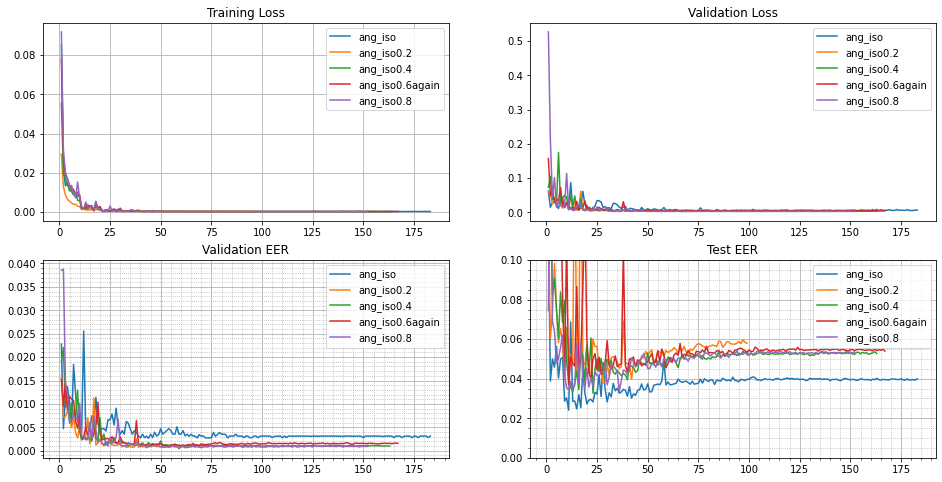

In [27]:
exp_dirs = ["ang_iso", "ang_iso0.2", "ang_iso0.4", "ang_iso0.6again", "ang_iso0.8"]
compare_exps(exp_dirs, "/data/neil/analyse/models1230")

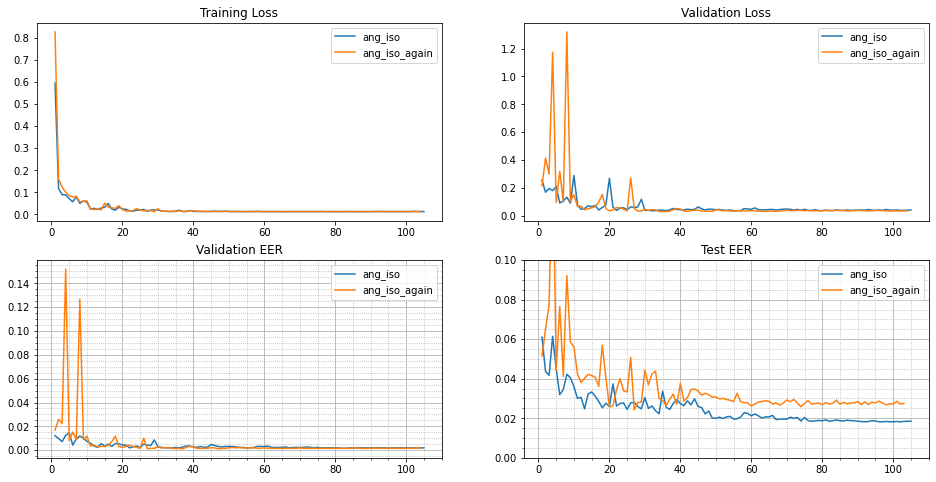

In [23]:
exp_dirs = ["ang_iso", "ang_iso_again"]
compare_exps(exp_dirs, "/data/neil/analyse/models1227")

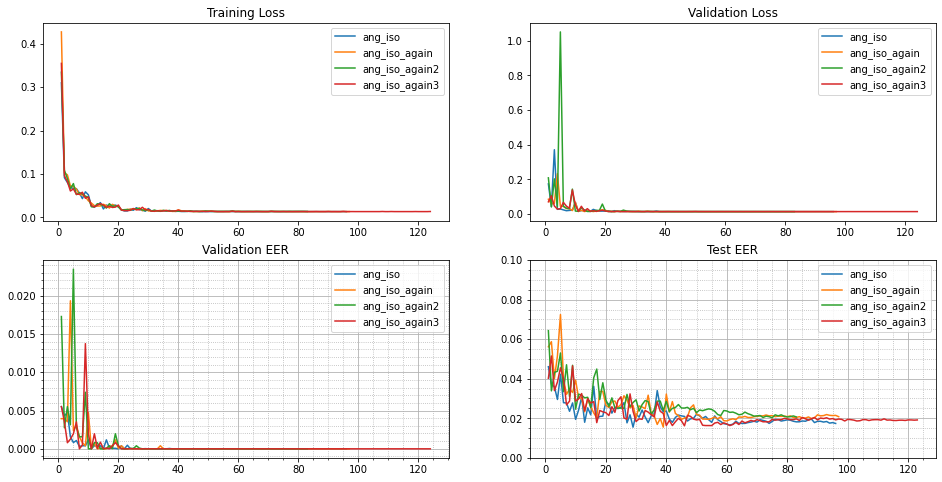

In [6]:
exp_dirs = ["ang_iso", "ang_iso_again", "ang_iso_again2", "ang_iso_again3"]
compare_exps(exp_dirs, "/data/neil/analyse/models0104")

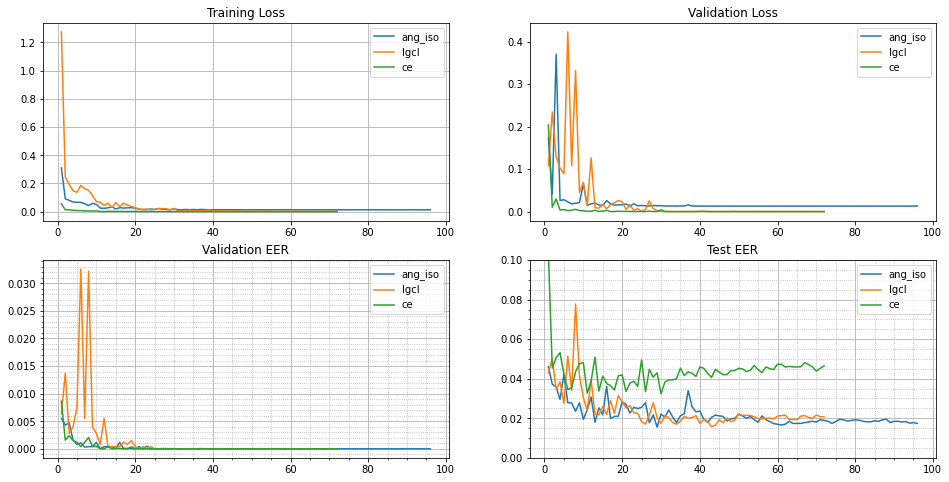

In [4]:
exp_dirs = ["ang_iso", "lgcl", "ce"]
compare_exps(exp_dirs, "/data/neil/analyse/models0104")

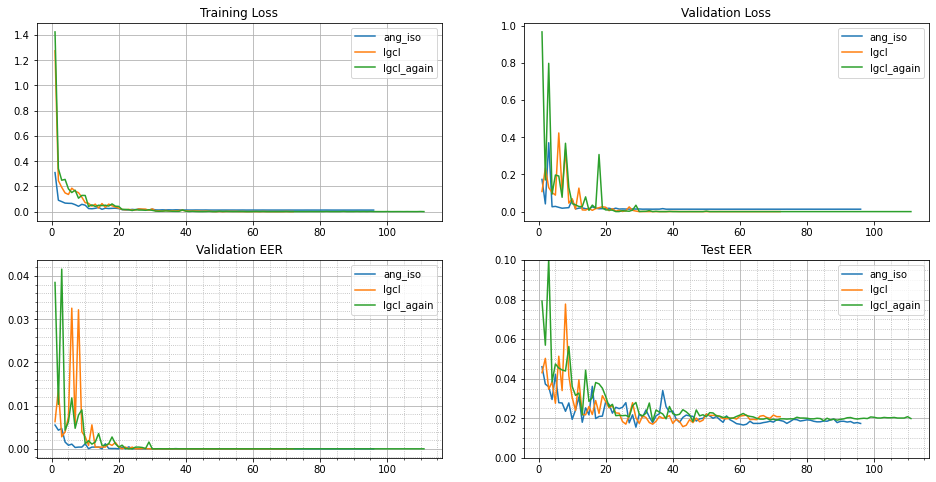

In [5]:
exp_dirs = ["ang_iso", "lgcl", "lgcl_again"]
compare_exps(exp_dirs, "/data/neil/analyse/models0104")

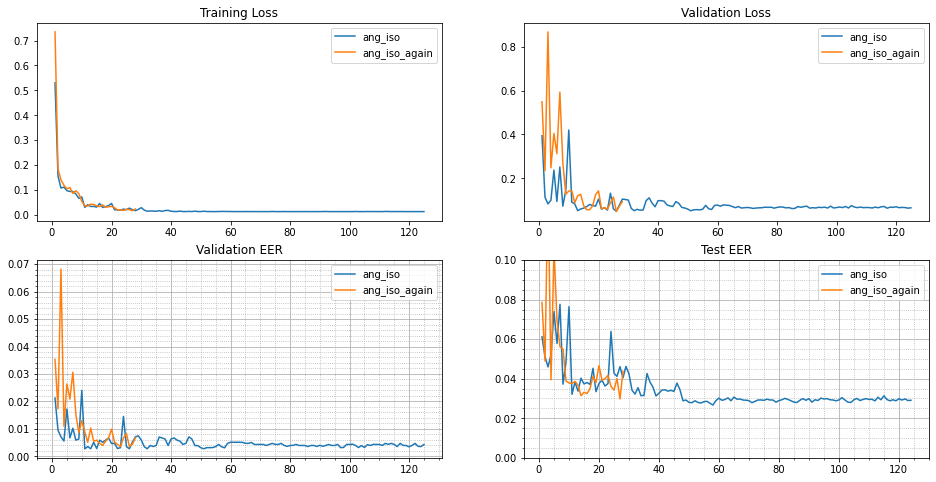

In [6]:
exp_dirs = ["ang_iso", "ang_iso_again"]
compare_exps(exp_dirs, "/data/neil/analyse/models0105")

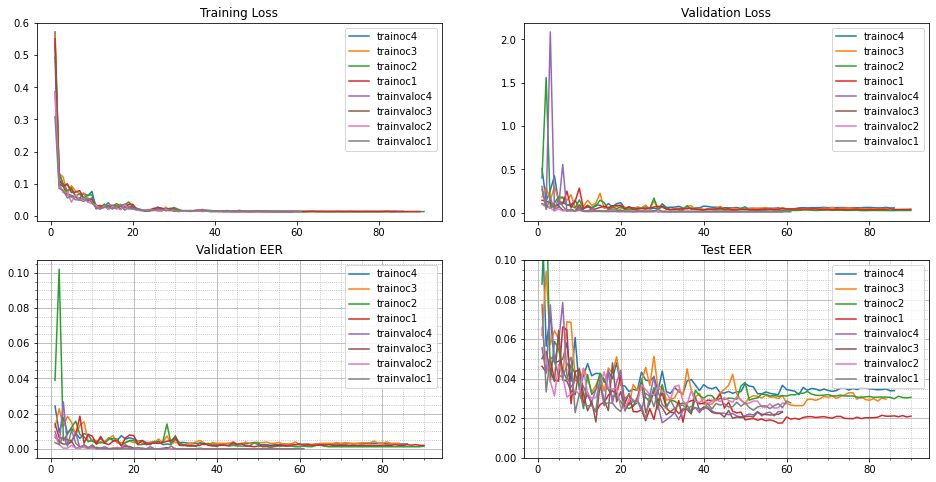

In [9]:
exp_dirs = ["trainoc4", "trainoc3", "trainoc2", "trainoc1", "trainvaloc4", "trainvaloc3", "trainvaloc2", "trainvaloc1"]
compare_exps(exp_dirs, "/data2/neil/analyse/models0110")

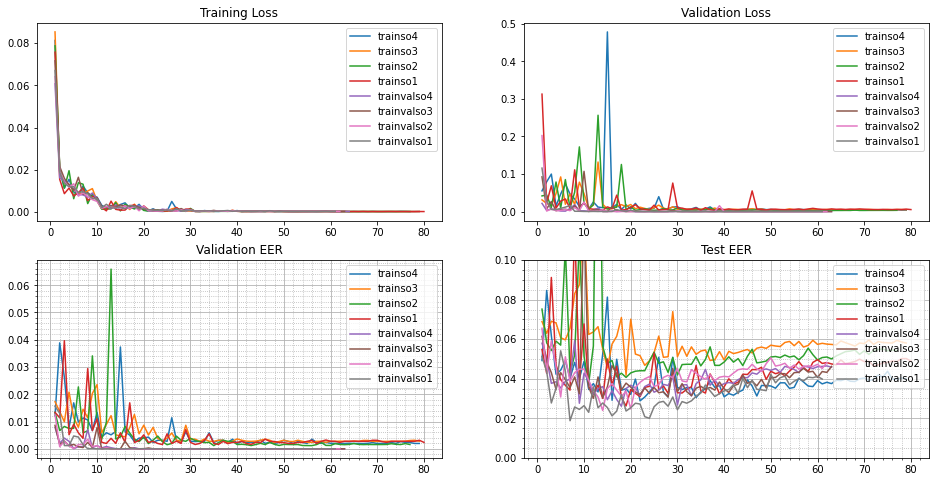

In [10]:
exp_dirs = ["trainso4", "trainso3", "trainso2", "trainso1", "trainvalso4", "trainvalso3", "trainvalso2", "trainvalso1"]
compare_exps(exp_dirs, "/data2/neil/analyse/models0110")

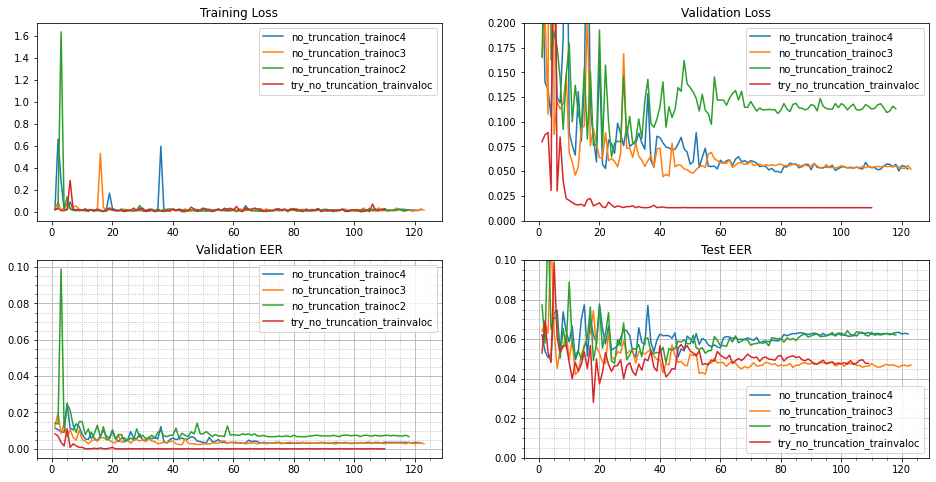

In [5]:
exp_dirs = ["no_truncation_trainoc4", "no_truncation_trainoc3", "no_truncation_trainoc2", "try_no_truncation_trainvaloc"]
compare_exps(exp_dirs, "/data2/neil/analyse/models0113")